# Random Forest por actividad productiva (municipios rurales) — validación agrupada por municipio y por departamento

> **Copia de `random_forest.ipynb` con dos agrupaciones.** Mismos datos, mismas 15 variables, misma variable
> objetivo (tasa de deforestación > 0) y misma partición temporal (entrenamiento 2021–2024, prueba 2025). Lo único
> que cambia es **cómo se agrupan las filas en la validación cruzada**, y aquí se corren las dos versiones lado a lado:
>
> - **Agrupación por municipio** (la del notebook original): un municipio nunca está a la vez en ajuste y validación.
> - **Agrupación por departamento** (la del gradient boosting del equipo, `modelos y clusters/gradient_boosting.ipynb`):
>   todos los municipios de un departamento quedan en el mismo pliegue, así que el modelo se valida en territorios
>   completos que no vio. Es más exigente, porque los municipios vecinos se parecen (mismo bosque, mismas vías,
>   mismo frente de colonización).
>
> Cada agrupación hace su propia búsqueda de hiperparámetros y produce su propio modelo final. Además, se agrega una
> evaluación sobre todo 2021–2025 dejando fuera municipios o departamentos completos (paso 11), equivalente a la
> sección 6 del gradient boosting. El notebook original `random_forest.ipynb` no se modifica.

**Pregunta.** ¿El crédito agropecuario de cada cadena (FINAGRO), el área cosechada de cada cultivo (EVA) y la
ganadería (ICA) de un municipio en un año ayudan a anticipar si ese municipio **tendrá alguna deforestación**
(tasa de deforestación del IDEAM > 0) el año siguiente? ¿Cambia la respuesta según cómo se agrupe la validación?

**Pasos** (se omite el análisis exploratorio):

1. Carga de datos
2. Variable objetivo
3. Variables explicativas por actividad (rezagadas un año)
4. Selección de la muestra
5. Partición temporal: entrenamiento 2021–2024 / prueba 2025, y grupos (municipio y departamento)
6. Preprocesamiento adecuado para árboles
7. Búsqueda de hiperparámetros con `GridSearchCV`: una vez agrupando por municipio y otra por departamento
8. Modelos finales y error *out-of-bag*
9. Comparación de modelos en 2025: AUC
10. Comparación de modelos en 2025: matriz de confusión
11. Evaluación dejando territorios completos fuera (municipios o departamentos, 2021–2025)
12. **Importancia de las variables** en los dos modelos: impureza, permutación individual, por bloques y dependencia parcial
13. Comparación de especificaciones (estructural, principal, con persistencia)
14. Guardado
15. Conclusiones

## 1. Carga de datos

In [1]:
import os
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().resolve()
while not (RAIZ / "main_local.py").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40, "display.width", 200)
SEMILLA = 42

panel = pd.read_parquet("datos/analisis/municipio_anio.parquet")
print(panel.shape)

(6738, 28)


## 2. Variable objetivo

`deforesta` = 1 si la **tasa de deforestación del IDEAM** del municipio en el año *t* es **mayor que 0**; 0 si es
cero. La tasa es `def_ideam_ha / bosque_ideam_ha`. Como en la muestra todos los municipios tienen bosque, la
condición "tasa > 0" equivale a "perdió alguna superficie de bosque, aunque sea una fracción de hectárea". A diferencia del umbral anterior de 10 ha,
cualquier pérdida cuenta, incluso las muy pequeñas.

In [2]:
REGLA_OBJETIVO = "tasa_def_ideam > 0"

panel = panel.sort_values(["cod_dane", "anio"]).reset_index(drop=True)
panel["deforesta"] = np.where(panel.tasa_def_ideam.isna(), np.nan, (panel.tasa_def_ideam > 0).astype(float))

d = panel[panel.anio.between(2021, 2025)]
print("Pérdida de bosque (ha) en los municipio-año con tasa > 0:")
print(d.loc[d.deforesta == 1, "def_ideam_ha"].describe(percentiles=[0.1, 0.25, 0.5, 0.75]).round(2).to_string())

Pérdida de bosque (ha) en los municipio-año con tasa > 0:
count     2766.00
mean       220.01
std        985.41
min          0.06
10%          1.31
25%          3.62
50%         18.38
75%         94.25
max      17041.50


## 3. Variables explicativas por actividad productiva

Todas las variables de crédito, cultivos y ganado se toman del **año anterior** (*t − 1*), para reducir la
causalidad inversa. Montos y áreas se transforman con log(1 + x) porque son muy asimétricos y tienen muchos
ceros. Para un árbol, el logaritmo no cambia las particiones; se aplica para que las curvas de dependencia
parcial se lean en una escala razonable.

| # | Variable | Definición (en *t − 1*) | Fuente |
|---|---|---|---|
| 1 | `log_credito_ganaderia` | Crédito del eslabón de producción a ganadería (doble propósito, leche, carne), millones de pesos | FINAGRO |
| 2 | `log_credito_cafe` | Ídem, café | FINAGRO |
| 3 | `log_credito_arroz` | Ídem, arroz | FINAGRO |
| 4 | `log_credito_cacao` | Ídem, cacao | FINAGRO |
| 5 | `log_credito_palma` | Ídem, palma de aceite | FINAGRO |
| 6 | `log_credito_otras_cadenas` | Crédito de producción de las demás cadenas: total de producción menos las cinco anteriores | FINAGRO |
| 7 | `log_cosechada_cafe` | Hectáreas cosechadas de café | EVA |
| 8 | `log_cosechada_arroz` | Ídem, arroz | EVA |
| 9 | `log_cosechada_palma` | Ídem, palma de aceite | EVA |
| 10 | `log_cosechada_cacao` | Ídem, cacao | EVA |
| 11 | `log_cosechada_otros` | Hectáreas cosechadas de los demás cultivos: total menos los cuatro anteriores | EVA |
| 12 | `log_bovinos` | Inventario bovino (cabezas) | ICA |
| 13 | `log_bosque_inicial` | Hectáreas de bosque del municipio al inicio del panel (fija) | IDEAM |
| 14 | `region` | Región del municipio (categórica) | Municipios |
| 15 | `ruralidad` | Categoría de ruralidad (categórica) | Municipios |

`log_credito_otras_cadenas` es crédito del eslabón de **producción**. No incluye el crédito de transformación,
comercialización y servicios (el antiguo `log_credito_otro`), que ya no se usa.

También se construyen las variables del modelo anterior de 9 variables, solo para compararlo en el paso 9.

In [3]:
p = panel.copy()
CADENAS = {"ganaderia": "credito_ganaderia_produccion_mm", "cafe": "credito_cafe_produccion_mm",
           "arroz": "credito_arroz_produccion_mm", "cacao": "credito_cacao_produccion_mm",
           "palma": "credito_palma_produccion_mm"}
CULTIVOS = {"cafe": "cosechada_cafe_ha", "arroz": "cosechada_arroz_ha", "palma": "cosechada_palma_ha",
            "cacao": "cosechada_cacao_ha"}

p["credito_otras_cadenas_mm"] = (p.credito_produccion_mm - p[list(CADENAS.values())].sum(axis=1)).clip(lower=0)
p["cosechada_otros_ha"] = (p.area_cosechada_ha - p[list(CULTIVOS.values())].sum(axis=1, min_count=1)).clip(lower=0)

# Variables del modelo anterior (solo para comparar)
p["credito_otro_mm"] = (p.credito_mm - p.credito_produccion_mm).clip(lower=0)
cred_prod = p.credito_produccion_mm.replace(0, np.nan)
p["prop_cred_ganaderia_t"] = (p.credito_ganaderia_produccion_mm / cred_prod).fillna(0)
p["prop_cred_permanentes_t"] = (p[["credito_palma_produccion_mm", "credito_cacao_produccion_mm",
                                   "credito_cafe_produccion_mm"]].sum(axis=1) / cred_prod).fillna(0)

# Rezago de un anio dentro de cada municipio
g = p.groupby("cod_dane", observed=True)
assert (g.anio.diff().dropna() == 1).all(), "hay anios faltantes dentro de algun municipio"
a_rezagar = {**{f"log_credito_{k}": v for k, v in CADENAS.items()},
             "log_credito_otras_cadenas": "credito_otras_cadenas_mm",
             **{f"log_cosechada_{k}": v for k, v in CULTIVOS.items()},
             "log_cosechada_otros": "cosechada_otros_ha",
             "log_bovinos": "bovinos", "log_def_l1": "def_ideam_ha",
             # modelo anterior
             "log_credito_prod": "credito_produccion_mm", "log_credito_otro": "credito_otro_mm",
             "log_area_cosechada": "area_cosechada_ha"}
for nuevo, col in a_rezagar.items():
    p[nuevo] = np.log1p(g[col].shift(1))
p["prop_cred_ganaderia"] = g.prop_cred_ganaderia_t.shift(1)
p["prop_cred_permanentes"] = g.prop_cred_permanentes_t.shift(1)
p["log_bosque_inicial"] = np.log1p(p.bosque_ideam_inicial_ha)

CREDITO = [f"log_credito_{k}" for k in CADENAS] + ["log_credito_otras_cadenas"]
COSECHA = [f"log_cosechada_{k}" for k in CULTIVOS] + ["log_cosechada_otros"]
NUMERICAS = CREDITO + COSECHA + ["log_bovinos", "log_bosque_inicial"]
CATEGORICAS = ["region", "ruralidad"]
X_COLS = NUMERICAS + CATEGORICAS
NUMERICAS_ANT = ["log_credito_prod", "log_credito_otro", "prop_cred_ganaderia", "prop_cred_permanentes",
                 "log_area_cosechada", "log_bovinos", "log_bosque_inicial"]
print(f"{len(X_COLS)} variables: {len(CREDITO)} de credito, {len(COSECHA)} de cosecha, bovinos, bosque y 2 categoricas")

15 variables: 6 de credito, 5 de cosecha, bovinos, bosque y 2 categoricas


## 4. Selección de la muestra

Misma muestra del gradient boosting: años objetivo 2021–2025, municipios **rurales o rurales dispersos** y con
tasa de deforestación calculable (es decir, con bosque). Se verifica que las filas coincidan exactamente con
las del gradient boosting.

In [4]:
RURALES = ["Rural", "Rural disperso"]
BOSQUE_MIN_HA = 0  # sin minimo de bosque: misma muestra del gradient boosting

muestra = p[p.anio.between(2021, 2025) & p.ruralidad.isin(RURALES) & p.tasa_def_ideam.notna()].copy()
muestra["deforesta"] = muestra.deforesta.astype(int)
print(f"Filas: {len(muestra):,} | municipios: {muestra.cod_dane.nunique():,} | "
      f"0: {(muestra.deforesta == 0).sum():,} | 1: {(muestra.deforesta == 1).sum():,}")

# Verificacion: mismas filas (municipio, anio) que el gradient boosting
import json
celdas_gb = ["".join(c["source"]) for c in json.load(open("modelos y clusters/gradient_boosting.ipynb"))["cells"]]
ns_gb = {"np": np, "pd": pd, "DIR_ANALISIS": Path("datos/analisis")}
exec(celdas_gb[4], ns_gb)  # carga del panel y filtro rural del gradient boosting
exec(celdas_gb[6], ns_gb)  # sus 15 variables y su muestra
filas_gb = set(zip(ns_gb["muestra"].cod_dane.astype(str), ns_gb["muestra"].anio))
filas_propias = set(zip(muestra.cod_dane.astype(str), muestra.anio))
assert filas_gb == filas_propias, "la muestra no coincide con la del gradient boosting"
print("La muestra coincide exactamente con la del gradient boosting.")

Filas: 3,195 | municipios: 639 | 0: 1,176 | 1: 2,019
Filas: 3,852  ·  Municipios rurales: 642  ·  Años: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Filas utilizables (2021-2025, con bosque): 3,195
Municipios-año con deforestación > 0: 2,019 (63.2 %)
La muestra coincide exactamente con la del gradient boosting.


## 5. Partición temporal y grupos

**Entrenamiento: 2021, 2022, 2023 y 2024. Prueba: 2025.** El modelo aprende con cuatro años y se evalúa en un año
que no conoce. Es lo más parecido a su uso real: predecir el año siguiente con lo que se sabe hasta hoy.

Para la validación cruzada se guardan dos variables de grupo: el código DANE del municipio y el nombre del
departamento.

In [5]:
ANIOS_TRAIN, ANIOS_TEST = [2021, 2022, 2023, 2024], [2025]
train = muestra[muestra.anio.isin(ANIOS_TRAIN)]
test = muestra[muestra.anio.isin(ANIOS_TEST)]
X_train, y_train = train[X_COLS], train.deforesta
X_test, y_test = test[X_COLS], test.deforesta

# Dos agrupaciones para la validacion cruzada: por municipio (version original) y por departamento
# (la del gradient boosting del equipo)
AGRUPACIONES = {"municipio": "cod_dane", "departamento": "nombre_departamento"}
grupos_train = {ag: train[col].astype(str) for ag, col in AGRUPACIONES.items()}
for ag, gr in grupos_train.items():
    print(f"Agrupacion por {ag}: {gr.nunique()} grupos en el entrenamiento")

pd.DataFrame({"filas": [len(train), len(test)], "ceros": [(y_train == 0).sum(), (y_test == 0).sum()],
              "unos": [(y_train == 1).sum(), (y_test == 1).sum()], "tasa_deforesta": [y_train.mean(), y_test.mean()]},
             index=["entrenamiento 2021-2024", "prueba 2025"]).round(3)

Agrupacion por municipio: 639 grupos en el entrenamiento
Agrupacion por departamento: 31 grupos en el entrenamiento


,filas,ceros,unos,tasa_deforesta
entrenamiento 2021-2024,2556,947,1609,0.629
prueba 2025,639,229,410,0.642


## 6. Preprocesamiento adecuado para árboles

| Transformación | ¿Se necesita? | Por qué |
|---|---|---|
| **Imputación** | **Sí** | `RandomForestClassifier` no acepta `NaN`. Se usa la mediana o la moda, aprendidas solo en entrenamiento. |
| **One-hot** de categóricas | **Sí** | Los árboles necesitan números. Se usa *one-hot* completo, sin eliminar categorías. |
| **Estandarización** | **No** | Una división "x ≤ c" no cambia al reescalar x. Se comprueba abajo: las probabilidades coinciden salvo diferencias mínimas por empates numéricos. Cuando dos divisiones son igual de buenas, el redondeo de la escala puede decidir cuál se elige en algún árbol. |
| **Logaritmos** | Inofensivos | Son monótonos y no cambian las particiones. |

Además se revisan las **correlaciones fuertes** entre variables. No afectan la capacidad predictiva del bosque,
pero cuando dos variables están muy correlacionadas (por ejemplo, crédito al café y área de café) se reparten
la importancia. Por eso en el paso 11 se mide también la importancia por **bloques**.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def preprocesador(num=NUMERICAS, escalar=False):
    pasos_num = [("imp", SimpleImputer(strategy="median"))] + ([("esc", StandardScaler())] if escalar else [])
    return ColumnTransformer([
        ("num", Pipeline(pasos_num), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CATEGORICAS),
    ], verbose_feature_names_out=False)


rf_prueba = dict(n_estimators=200, random_state=SEMILLA, n_jobs=-1)
sin_esc = Pipeline([("pre", preprocesador()), ("rf", RandomForestClassifier(**rf_prueba))]).fit(X_train, y_train)
con_esc = Pipeline([("pre", preprocesador(escalar=True)), ("rf", RandomForestClassifier(**rf_prueba))]).fit(X_train, y_train)
dif = np.abs(sin_esc.predict_proba(X_test)[:, 1] - con_esc.predict_proba(X_test)[:, 1])
print(f"Diferencia de probabilidad con vs. sin estandarizar: maxima {dif.max():.3f} (1 arbol de 200 = 0.005) | "
      f"promedio {dif.mean():.5f} | filas identicas {np.mean(dif == 0):.1%}")
print(f"Columnas que recibe el bosque: {len(preprocesador().fit(X_train).get_feature_names_out())}")

corr = X_train[NUMERICAS].corr(method="spearman")
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho_spearman")
         .loc[lambda s: s.abs() >= 0.6].sort_values(key=abs, ascending=False))
print("\nPares con |correlacion de Spearman| >= 0,6:")
pares.round(3).to_frame()

Diferencia de probabilidad con vs. sin estandarizar: maxima 0.000 (1 arbol de 200 = 0.005) | promedio 0.00000 | filas identicas 100.0%
Columnas que recibe el bosque: 21

Pares con |correlacion de Spearman| >= 0,6:


,,rho_spearman
log_credito_cafe,log_cosechada_cafe,0.924
log_credito_ganaderia,log_bovinos,0.820
log_credito_palma,log_cosechada_palma,0.795
log_credito_cacao,log_cosechada_cacao,0.789
log_credito_arroz,log_cosechada_arroz,0.601


## 7. Búsqueda de hiperparámetros con `GridSearchCV`

| Hiperparámetro | Qué controla | Valores probados |
|---|---|---|
| `n_estimators` | número de árboles | 300, 600 |
| `max_depth` | profundidad máxima de cada árbol | 4, 8, 12, sin límite |
| `min_samples_leaf` | mínimo de observaciones por hoja | 1, 5, 10, 25 |
| `max_features` | proporción de variables sorteadas en cada división | `sqrt`, 0,5, todas |
| `class_weight` | peso de la clase minoritaria en cada muestra *bootstrap* | ninguno, `balanced_subsample` |

Son 192 combinaciones, evaluadas con `GroupKFold` de 5 pliegues. La búsqueda se corre **dos veces**:

- **Agrupada por municipio:** un municipio nunca está a la vez en ajuste y validación (versión original).
- **Agrupada por departamento:** cada pliegue de validación tiene departamentos completos (unos 6 de los 31), igual
  que en el gradient boosting. Ningún municipio se valida con un vecino de su mismo departamento en el ajuste.

La métrica es el AUC-ROC, y también se registra el AUC de entrenamiento para ver el sobreajuste. Al final se cruza
cada combinación ganadora con su puntaje en la otra agrupación.

In [7]:
from sklearn.model_selection import GridSearchCV, GroupKFold

modelo = Pipeline([("pre", preprocesador()), ("rf", RandomForestClassifier(random_state=SEMILLA, n_jobs=1))])
grilla = {
    "rf__n_estimators": [300, 600],
    "rf__max_depth": [4, 8, 12, None],
    "rf__min_samples_leaf": [1, 5, 10, 25],
    "rf__max_features": ["sqrt", 0.5, 1.0],
    "rf__class_weight": [None, "balanced_subsample"],
}
HIPER = ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight"]
cols = {f"param_rf__{k}": k for k in HIPER}
cols.update({"mean_test_roc_auc": "AUC_val", "std_test_roc_auc": "AUC_val_sd", "mean_train_roc_auc": "AUC_train",
             "mean_test_average_precision": "AP_val", "mean_test_neg_log_loss": "neg_logloss_val"})

busquedas, tablas_cv = {}, {}
for ag in AGRUPACIONES:
    busqueda = GridSearchCV(modelo, grilla, cv=GroupKFold(n_splits=5),
                            scoring=["roc_auc", "average_precision", "neg_log_loss"],
                            refit="roc_auc", n_jobs=-1, return_train_score=True)
    inicio = time.time()
    busqueda.fit(X_train, y_train, groups=grupos_train[ag])
    print(f"[CV por {ag}] {len(busqueda.cv_results_['params'])} combinaciones x 5 pliegues en "
          f"{(time.time() - inicio) / 60:.1f} min | mejor AUC validacion: {busqueda.best_score_:.4f}")
    t = pd.DataFrame(busqueda.cv_results_)[list(cols)].rename(columns=cols)
    t["brecha_train_val"] = t.AUC_train - t.AUC_val
    busquedas[ag], tablas_cv[ag] = busqueda, t.sort_values("AUC_val", ascending=False)

mejores = {ag: {k.replace("rf__", ""): v for k, v in b.best_params_.items()} for ag, b in busquedas.items()}

# Cruce: cada combinacion ganadora, evaluada con las dos agrupaciones
# (la fila ganadora se toma de best_index_: con empates, el orden de la tabla puede no coincidir)
clave = lambda t: t[HIPER].astype(str).agg("|".join, axis=1)
auc_por = {ag: t.set_index(clave(t)).AUC_val for ag, t in tablas_cv.items()}
ganadora = {ag: tablas_cv[ag].loc[[b.best_index_]] for ag, b in busquedas.items()}
resumen_cv = pd.DataFrame({
    f"elegida con CV por {ag}": {**{k: str(v) for k, v in mejores[ag].items()},
                                 **{f"AUC_val CV por {otra}": auc_por[otra][clave(ganadora[ag]).iloc[0]] for otra in AGRUPACIONES},
                                 "AUC_train": ganadora[ag].AUC_train.iloc[0]}
    for ag in AGRUPACIONES})
display(resumen_cv)
print("Las 5 mejores combinaciones de cada busqueda:")
pd.concat({f"CV por {ag}": t.head(5).reset_index(drop=True) for ag, t in tablas_cv.items()}).round(4)

[CV por municipio] 192 combinaciones x 5 pliegues en 5.8 min | mejor AUC validacion: 0.9111


[CV por departamento] 192 combinaciones x 5 pliegues en 6.8 min | mejor AUC validacion: 0.8991


,elegida con CV por municipio,elegida con CV por departamento
class_weight,None,None
max_depth,12,8
max_features,0.5,1.0
min_samples_leaf,25,25
n_estimators,300,600
AUC_val CV por municipio,0.911098,0.910039
AUC_val CV por departamento,0.897931,0.899109
AUC_train,0.944586,0.947044


Las 5 mejores combinaciones de cada busqueda:


n_estimators max_depth  min_samples_leaf max_features class_weight  AUC_val  AUC_val_sd  AUC_train  AP_val  neg_logloss_val  brecha_train_val
CV por municipio    0           300      None                25          0.5         None   0.9111      0.0084     0.9446  0.9496          -0.3627            0.0335
                    1           300        12                25          0.5         None   0.9111      0.0084     0.9446  0.9496          -0.3627            0.0335
                    2           300         8                25          0.5         None   0.9111      0.0083     0.9445  0.9496          -0.3626            0.0334
                    3           600         8                25          0.5         None   0.9109      0.0085     0.9445  0.9495          -0.3631            0.0337
                    4           600        12                25          0.5         None   0.9108      0.0084     0.9447  0.9494          -0.3633            0.0339
CV por departamento 0           600         8                25          1.0         None   0.8991      0.0201     0.9470  0.9366          -0.3761            0.0479
                    1           600        12                25          1.0         None   0.8991      0.0200     0.9471  0.9366          -0.3761            0.0480
                    2           600      None                25          1.0         None   0.8991      0.0200     0.9471  0.9366          -0.3761            0.0480
                    3           300      None                25          1.0         None   0.8991      0.0200     0.9471  0.9367          -0.3762            0.0481
                    4           300        12                25          1.0         None   0.8991      0.0200     0.9471  0.9367          -0.3762            0.0481

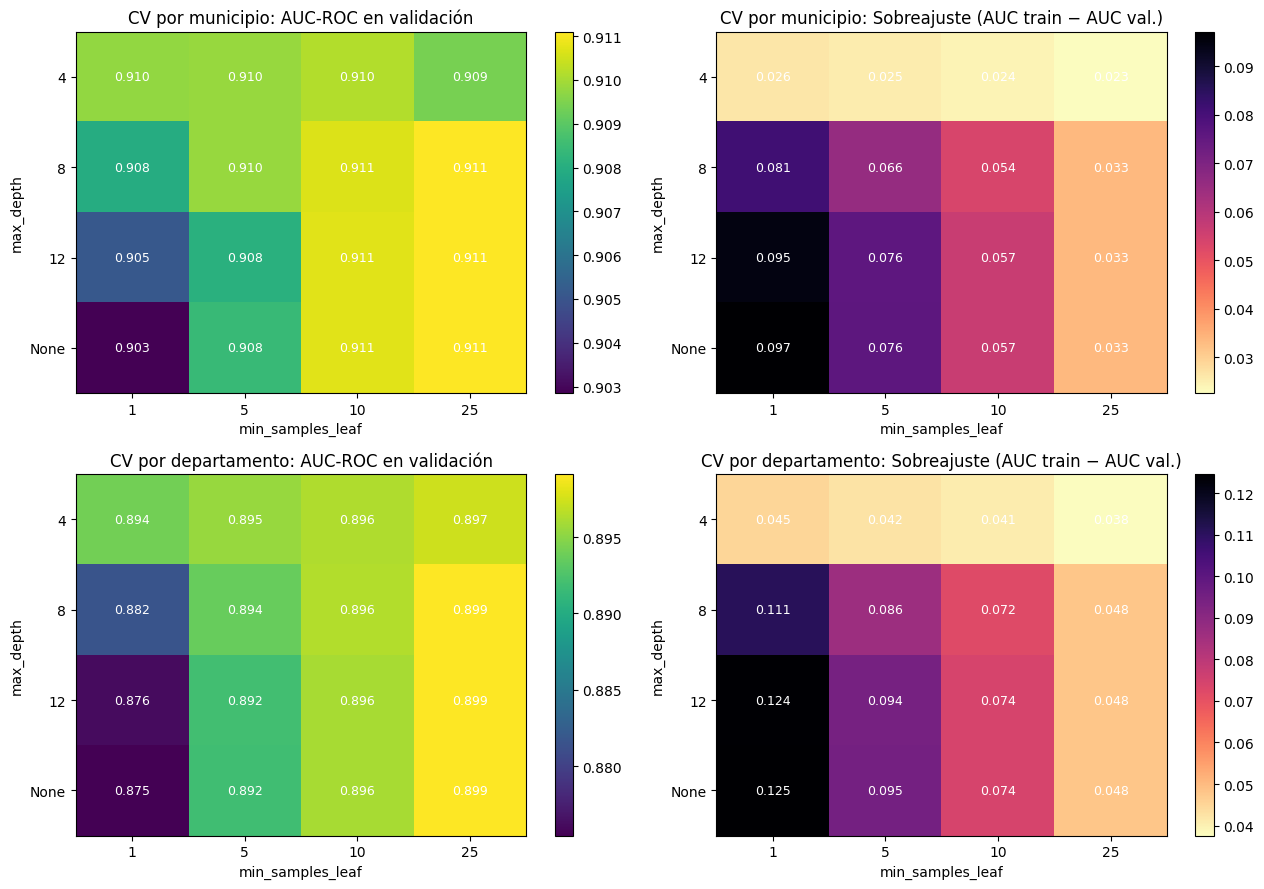

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for fila, ag in enumerate(AGRUPACIONES):
    mejor = busquedas[ag].best_params_
    t = tablas_cv[ag]
    fijo = t[(t.n_estimators == mejor["rf__n_estimators"]) & (t.max_features.astype(str) == str(mejor["rf__max_features"]))
             & (t.class_weight.astype(str) == str(mejor["rf__class_weight"]))].copy()
    fijo["max_depth"] = fijo.max_depth.astype(str)
    for metrica, eje, titulo in [("AUC_val", ax[fila, 0], "AUC-ROC en validación"),
                                 ("brecha_train_val", ax[fila, 1], "Sobreajuste (AUC train − AUC val.)")]:
        tabla = fijo.pivot_table(index="max_depth", columns="min_samples_leaf", values=metrica).reindex(["4", "8", "12", "None"])
        im = eje.imshow(tabla.values, cmap="viridis" if metrica == "AUC_val" else "magma_r", aspect="auto")
        eje.set_xticks(range(tabla.shape[1]), tabla.columns); eje.set_yticks(range(tabla.shape[0]), tabla.index)
        eje.set_xlabel("min_samples_leaf"); eje.set_ylabel("max_depth"); eje.set_title(f"CV por {ag}: {titulo}")
        for i in range(tabla.shape[0]):
            for j in range(tabla.shape[1]):
                eje.text(j, i, f"{tabla.values[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
        plt.colorbar(im, ax=eje)
plt.tight_layout(); plt.show()

## 8. Modelos finales y error *out-of-bag*

Cada `GridSearchCV` re-entrena su mejor combinación con todo el entrenamiento (2021–2024), así que hay dos modelos
finales: el elegido con la validación por municipio y el elegido con la validación por departamento. Como chequeo,
cada bosque se ajusta también con `oob_score=True`. El OOB es algo optimista aquí, porque las filas que quedan fuera
de un árbol pueden ser otros años del mismo municipio.

In [9]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

finales = {ag: b.best_estimator_ for ag, b in busquedas.items()}
filas = []
for ag, f in finales.items():
    oob = clone(f).set_params(rf__oob_score=True, rf__n_jobs=-1).fit(X_train, y_train)
    filas.append({"agrupacion_cv": ag, **{k: str(v) for k, v in mejores[ag].items()},
                  "AUC_oob": roc_auc_score(y_train, oob.named_steps["rf"].oob_decision_function_[:, 1]),
                  "AUC_validacion_cruzada": busquedas[ag].best_score_})
pd.DataFrame(filas).set_index("agrupacion_cv").round(4)

,class_weight,max_depth,max_features,min_samples_leaf,n_estimators,AUC_oob,AUC_validacion_cruzada
agrupacion_cv,,,,,,,
municipio,None,12,0.5,25,300,0.9218,0.9111
departamento,None,8,1.0,25,600,0.9215,0.8991


## 9. Comparación de modelos: AUC

Los modelos se comparan sobre los mismos 639 municipios de 2025 con el **AUC-ROC**: la probabilidad de que un
municipio que deforestó reciba una probabilidad mayor que uno que no deforestó (0,5 = azar, 1 = perfecto).

- **RF por actividad — CV por municipio:** hiperparámetros elegidos agrupando por municipio.
- **RF por actividad — CV por departamento:** hiperparámetros elegidos agrupando por departamento.
- **RF de totales (9 variables):** las variables de `modelo_random_forest.ipynb` y sus hiperparámetros (600 árboles,
  `max_depth = 12`, `min_samples_leaf = 10`), re-entrenado con la misma variable objetivo y el mismo entrenamiento.
- **Gradient boosting (equipo):** el modelo guardado de `modelos y clusters/gradient_boosting.ipynb`, con sus
  propias 15 variables (del mismo año que predice), cuyos hiperparámetros se eligieron agrupando por departamento.
- **Persistencia:** asigna la probabilidad observada en el entrenamiento según si el municipio deforestó o no el
  año anterior.

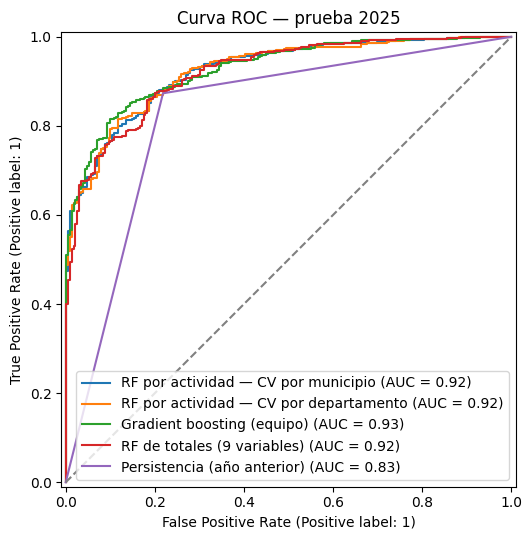

Correlacion entre las probabilidades de los dos RF: 0.9951


,AUC-ROC
RF por actividad — CV por municipio,0.9246
RF por actividad — CV por departamento,0.9245
Gradient boosting (equipo),0.9278
RF de totales (9 variables),0.9204
Persistencia (año anterior),0.8274


In [10]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score


def metricas(y, prob):
    return {"AUC-ROC": roc_auc_score(y, prob)}


PARAMS_ANT = dict(n_estimators=600, max_depth=12, min_samples_leaf=10, max_features="sqrt", class_weight=None)
anterior = Pipeline([("pre", preprocesador(NUMERICAS_ANT)),
                     ("rf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1, **PARAMS_ANT))])
anterior.fit(train[NUMERICAS_ANT + CATEGORICAS], y_train)

p["deforesta_l1"] = p.groupby("cod_dane", observed=True).deforesta.shift(1)
tasa_cond = train.assign(l1=p.loc[train.index, "deforesta_l1"]).groupby("l1").deforesta.mean()

ETIQUETA = {ag: f"RF por actividad — CV por {ag}" for ag in AGRUPACIONES}
prob_test = {ag: f.predict_proba(X_test)[:, 1] for ag, f in finales.items()}
prob_ant = anterior.predict_proba(test[NUMERICAS_ANT + CATEGORICAS])[:, 1]
prob_pers = p.loc[test.index, "deforesta_l1"].map(tasa_cond).fillna(y_train.mean()).values

# --- Gradient boosting del equipo, sobre los mismos municipios de 2025
import joblib
import lightgbm  # noqa: F401  (necesario para cargar el modelo)
test_gb = ns_gb["muestra"].query("anio == 2025").assign(cod_dane=lambda d: d.cod_dane.astype(str)).set_index("cod_dane")
gb = joblib.load("modelos y clusters/resultados/gradient_boosting_clasificador.joblib")
prob_gb = gb.predict_proba(test_gb.loc[test.cod_dane.astype(str), ns_gb["EXPLICATIVAS"]])[:, 1]
modelos = {ETIQUETA["municipio"]: prob_test["municipio"], ETIQUETA["departamento"]: prob_test["departamento"],
           "Gradient boosting (equipo)": prob_gb, "RF de totales (9 variables)": prob_ant,
           "Persistencia (año anterior)": prob_pers}
tabla_eval = pd.DataFrame({k: metricas(y_test, v) for k, v in modelos.items()}).T

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nombre, prob in modelos.items():
    RocCurveDisplay.from_predictions(y_test, prob, ax=ax, name=nombre)
ax.plot([0, 1], [0, 1], "--", color="grey"); ax.set_title("Curva ROC — prueba 2025")
plt.tight_layout(); plt.show()
print(f"Correlacion entre las probabilidades de los dos RF: {np.corrcoef(prob_test['municipio'], prob_test['departamento'])[0, 1]:.4f}")
tabla_eval.round(4)

## 10. Comparación de modelos: matriz de confusión

Cada modelo clasifica los municipios de 2025 con el **mismo umbral de 0,5**: si la probabilidad predicha es
0,5 o más, se clasifica como "deforesta". Usar el mismo umbral permite comparar los modelos directamente, y
0,5 es también el umbral que usa el gradient boosting (`predict`).

- **Verdaderos positivos:** municipios que deforestaron y el modelo los detectó.
- **Falsos negativos:** municipios que deforestaron y el modelo no los detectó.
- **Falsos positivos:** municipios que no deforestaron pero el modelo los marcó.
- **Verdaderos negativos:** municipios que no deforestaron y el modelo acertó.

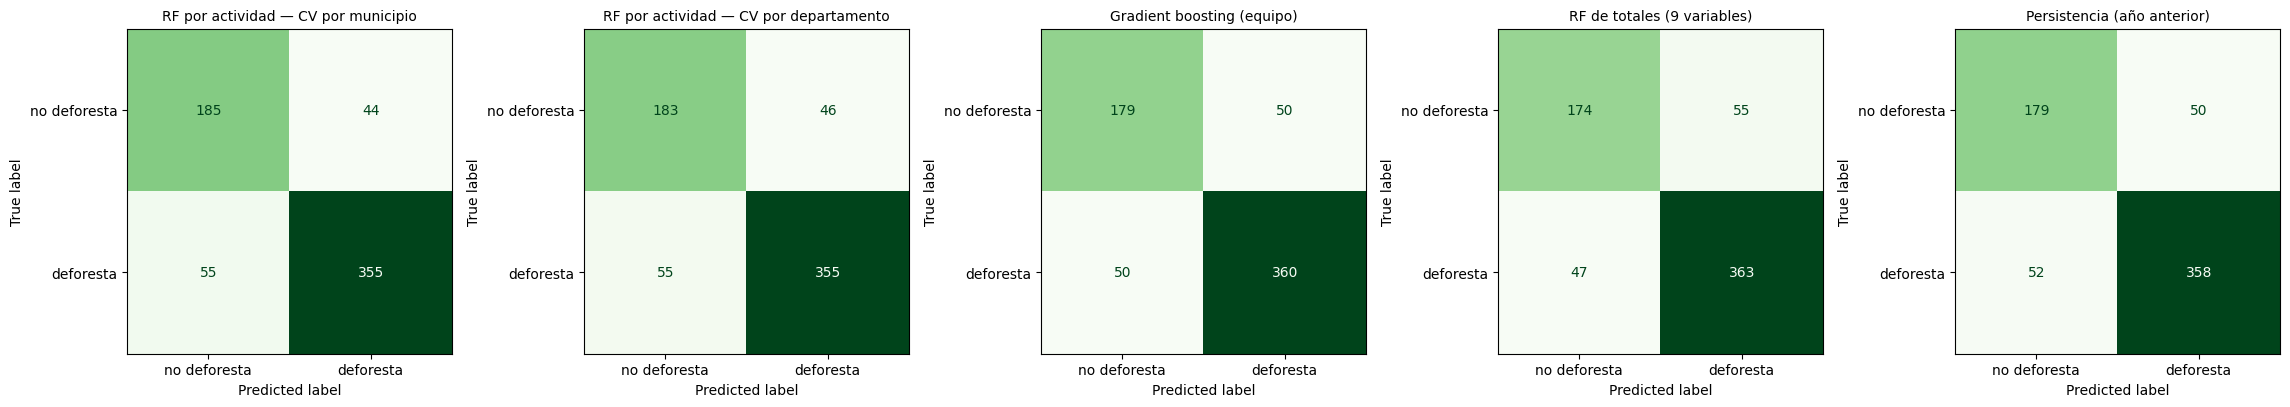

,verdaderos negativos,falsos positivos,falsos negativos,verdaderos positivos,aciertos
modelo,,,,,
RF por actividad — CV por municipio,185,44,55,355,540
RF por actividad — CV por departamento,183,46,55,355,538
Gradient boosting (equipo),179,50,50,360,539
RF de totales (9 variables),174,55,47,363,537
Persistencia (año anterior),179,50,52,358,537


In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

UMBRAL = 0.5
fig, ax = plt.subplots(1, len(modelos), figsize=(4.6 * len(modelos), 4.3))
filas = []
for eje, (nombre, prob) in zip(np.atleast_1d(ax), modelos.items()):
    pred = (prob >= UMBRAL).astype(int)
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["no deforesta", "deforesta"]).plot(ax=eje, cmap="Greens", colorbar=False)
    eje.set_title(nombre, fontsize=10)
    tn, fp, fn, tp = cm.ravel()
    filas.append({"modelo": nombre, "verdaderos negativos": tn, "falsos positivos": fp,
                  "falsos negativos": fn, "verdaderos positivos": tp, "aciertos": tn + tp})
plt.tight_layout(); plt.show()
pred_test = {ag: (prob_test[ag] >= UMBRAL).astype(int) for ag in AGRUPACIONES}
matrices = pd.DataFrame(filas).set_index("modelo")
matrices

## 11. Evaluación dejando territorios completos fuera (2021–2025)

Los pasos 9 y 10 miden la generalización **en el tiempo** (entrena 2021–2024, prueba 2025), pero los 639 municipios
de la prueba son los mismos que el modelo vio en entrenamiento. Aquí se mide la generalización **en el territorio**,
igual que la sección 6 del gradient boosting: `GroupKFold` de 5 pliegues sobre **todo 2021–2025**, con los
hiperparámetros ya elegidos (sin volver a buscar). En cada pliegue se entrena con los grupos restantes y se predice
el grupo que quedó fuera, así que cada fila queda predicha por un modelo que nunca vio su municipio (o su
departamento).

Se cruzan las dos agrupaciones: los hiperparámetros elegidos con cada CV se evalúan dejando fuera municipios y
dejando fuera departamentos. Como referencia se muestra el resultado del gradient boosting con departamentos fuera
(de `gradient_boosting_metricas.csv`). Con la misma muestra y los mismos nombres de departamento, `GroupKFold` arma
los mismos pliegues que en el gradient boosting.

In [12]:
from sklearn.metrics import balanced_accuracy_score

m_todo = muestra.reset_index(drop=True)
X_todo, y_todo = m_todo[X_COLS], m_todo.deforesta
filas, prob_oof = [], {}
for ag_hp, f in finales.items():
    for ag_eval, col in AGRUPACIONES.items():
        prob = np.full(len(m_todo), np.nan)
        for i_dentro, i_fuera in GroupKFold(n_splits=5).split(X_todo, y_todo, groups=m_todo[col].astype(str)):
            mod = clone(f).set_params(rf__n_jobs=-1).fit(X_todo.iloc[i_dentro], y_todo.iloc[i_dentro])
            prob[i_fuera] = mod.predict_proba(X_todo.iloc[i_fuera])[:, 1]
        prob_oof[(ag_hp, ag_eval)] = prob
        pred = (prob >= UMBRAL).astype(int)
        filas.append({"modelo": ETIQUETA[ag_hp], "evaluacion": f"{ag_eval}s fuera", "AUC-ROC": roc_auc_score(y_todo, prob),
                      "exactitud balanceada": balanced_accuracy_score(y_todo, pred), "aciertos %": 100 * (pred == y_todo).mean()})

gb_met = pd.read_csv("modelos y clusters/resultados/gradient_boosting_metricas.csv")
gb_met = gb_met[gb_met.modelo.str.contains("deforesta")].set_index("métrica").prueba_departamentos_fuera
filas.append({"modelo": "Gradient boosting (equipo)", "evaluacion": "departamentos fuera", "AUC-ROC": gb_met["AUC"],
              "exactitud balanceada": gb_met["exactitud balanceada"], "aciertos %": np.nan})
eval_territorio = pd.DataFrame(filas)
print(f"Filas evaluadas: {len(m_todo):,} (2021-2025) | departamentos: {m_todo.nombre_departamento.astype(str).nunique()}")
eval_territorio.pivot(index="modelo", columns="evaluacion", values=["AUC-ROC", "exactitud balanceada"]).round(4)

Filas evaluadas: 3,195 (2021-2025) | departamentos: 31


AUC-ROC                  exactitud balanceada                 
evaluacion                             departamentos fuera municipios fuera  departamentos fuera municipios fuera
modelo                                                                                                           
Gradient boosting (equipo)                          0.9088              NaN               0.8132              NaN
RF por actividad — CV por departamento              0.9070           0.9107               0.8136           0.8139
RF por actividad — CV por municipio                 0.9064           0.9122               0.8126           0.8159

## 12. Importancia de las variables (en los dos modelos)

Se calculan cuatro medidas:

1. **Impureza (MDI)**: reducción de Gini en el entrenamiento. Las columnas *one-hot* se suman por variable
   original. Favorece a las variables continuas con muchos valores.
2. **Permutación individual** (en la **prueba 2025**): caída del AUC al desordenar una variable, con 30 repeticiones.
3. **Permutación por bloques temáticos**: se desordenan **juntas** todas las variables de un bloque (todo el
   crédito, toda la cosecha...). Así no se subestiman variables correlacionadas entre sí.
4. **Permutación por actividad productiva**: se desordenan juntos el crédito y el área de cada actividad
   (crédito y área de café; crédito ganadero y bovinos...). Responde cuánto aporta cada actividad en conjunto.

In [13]:
from sklearn.inspection import permutation_importance

original = lambda c: next((v for v in CATEGORICAS if c.startswith(v + "_")), c)
importancia, perms = {}, {}
for ag, f in finales.items():
    rf = f.named_steps["rf"]
    nombres = pd.Index(f.named_steps["pre"].get_feature_names_out())
    mdi = pd.Series(rf.feature_importances_, index=nombres).groupby(nombres.map(original)).sum()
    mdi_sd = pd.Series(np.std([a.feature_importances_ for a in rf.estimators_], axis=0), index=nombres).groupby(nombres.map(original)).sum()
    perms[ag] = permutation_importance(f, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEMILLA, n_jobs=-1)
    t = pd.DataFrame({"MDI": mdi, "MDI_sd": mdi_sd,
                      "permutacion_caida_AUC": pd.Series(perms[ag].importances_mean, index=X_COLS),
                      "permutacion_sd": pd.Series(perms[ag].importances_std, index=X_COLS)})
    t["rango_MDI"] = t.MDI.rank(ascending=False).astype(int)
    t["rango_permutacion"] = t.permutacion_caida_AUC.rank(ascending=False).astype(int)
    importancia[ag] = t.sort_values("permutacion_caida_AUC", ascending=False)

pd.concat({f"CV por {ag}": t for ag, t in importancia.items()}, axis=1).sort_values(
    ("CV por departamento", "permutacion_caida_AUC"), ascending=False).round(4)

CV por municipio                                                                          CV por departamento                                                         \
                                       MDI  MDI_sd permutacion_caida_AUC permutacion_sd rango_MDI rango_permutacion                 MDI  MDI_sd permutacion_caida_AUC permutacion_sd rango_MDI   
log_bosque_inicial                  0.6454  0.1513                0.3080         0.0142         1                 1              0.7737  0.0211                0.3633         0.0166         1   
log_cosechada_cacao                 0.1053  0.1042                0.0193         0.0033         2                 2              0.0571  0.0223                0.0210         0.0033         2   
log_bovinos                         0.0539  0.0433                0.0094         0.0021         3                 4              0.0478  0.0254                0.0153         0.0029         3   
region                              0.0422  0.0822                0.0111         0.0019         4                 3              0.0161  0.0319                0.0069         0.0012         6   
log_credito_ganaderia               0.0246  0.0316                0.0026         0.0006         7                 5              0.0208  0.0131                0.0044         0.0009         5   
log_cosechada_cafe                  0.0325  0.0212                0.0013         0.0013         6                10              0.0277  0.0137                0.0035         0.0018         4   
log_credito_otras_cadenas           0.0127  0.0141                0.0015         0.0005        10                 9              0.0132  0.0098                0.0021         0.0006         9   
log_credito_cafe                    0.0202  0.0172                0.0017         0.0007         8                 7              0.0146  0.0112                0.0017         0.0006         7   
log_cosechada_otros                 0.0142  0.0131                0.0015         0.0006         9                 8              0.0139  0.0101                0.0017         0.0006         8   
log_credito_cacao                   0.0331  0.0512                0.0017         0.0010         5                 6              0.0099  0.0119                0.0011         0.0005        10   
log_cosechada_arroz                 0.0088  0.0218                0.0010         0.0003        11                11              0.0028  0.0080                0.0005         0.0002        11   
ruralidad                           0.0030  0.0107               -0.0000         0.0002        12                15              0.0014  0.0044                0.0004         0.0002        12   
log_credito_arroz                   0.0026  0.0073                0.0001         0.0002        13                13              0.0005  0.0025                0.0001         0.0000        14   
log_credito_palma                   0.0004  0.0041                0.0000         0.0001        15                14              0.0000  0.0002                0.0000         0.0000        15   
log_cosechada_palma                 0.0011  0.0037                0.0001         0.0001        14                12              0.0006  0.0024               -0.0001         0.0001        13   

                                             
                          rango_permutacion  
log_bosque_inicial                        1  
log_cosechada_cacao                       2  
log_bovinos                               3  
region                                    4  
log_credito_ganaderia                     5  
log_cosechada_cafe                        6  
log_credito_otras_cadenas                 7  
log_credito_cafe                          8  
log_cosechada_otros                       9  
log_credito_cacao                        10  
log_cosechada_arroz                      11  
ruralidad                                12  
log_credito_arroz                        13  
log_credito_palma                    

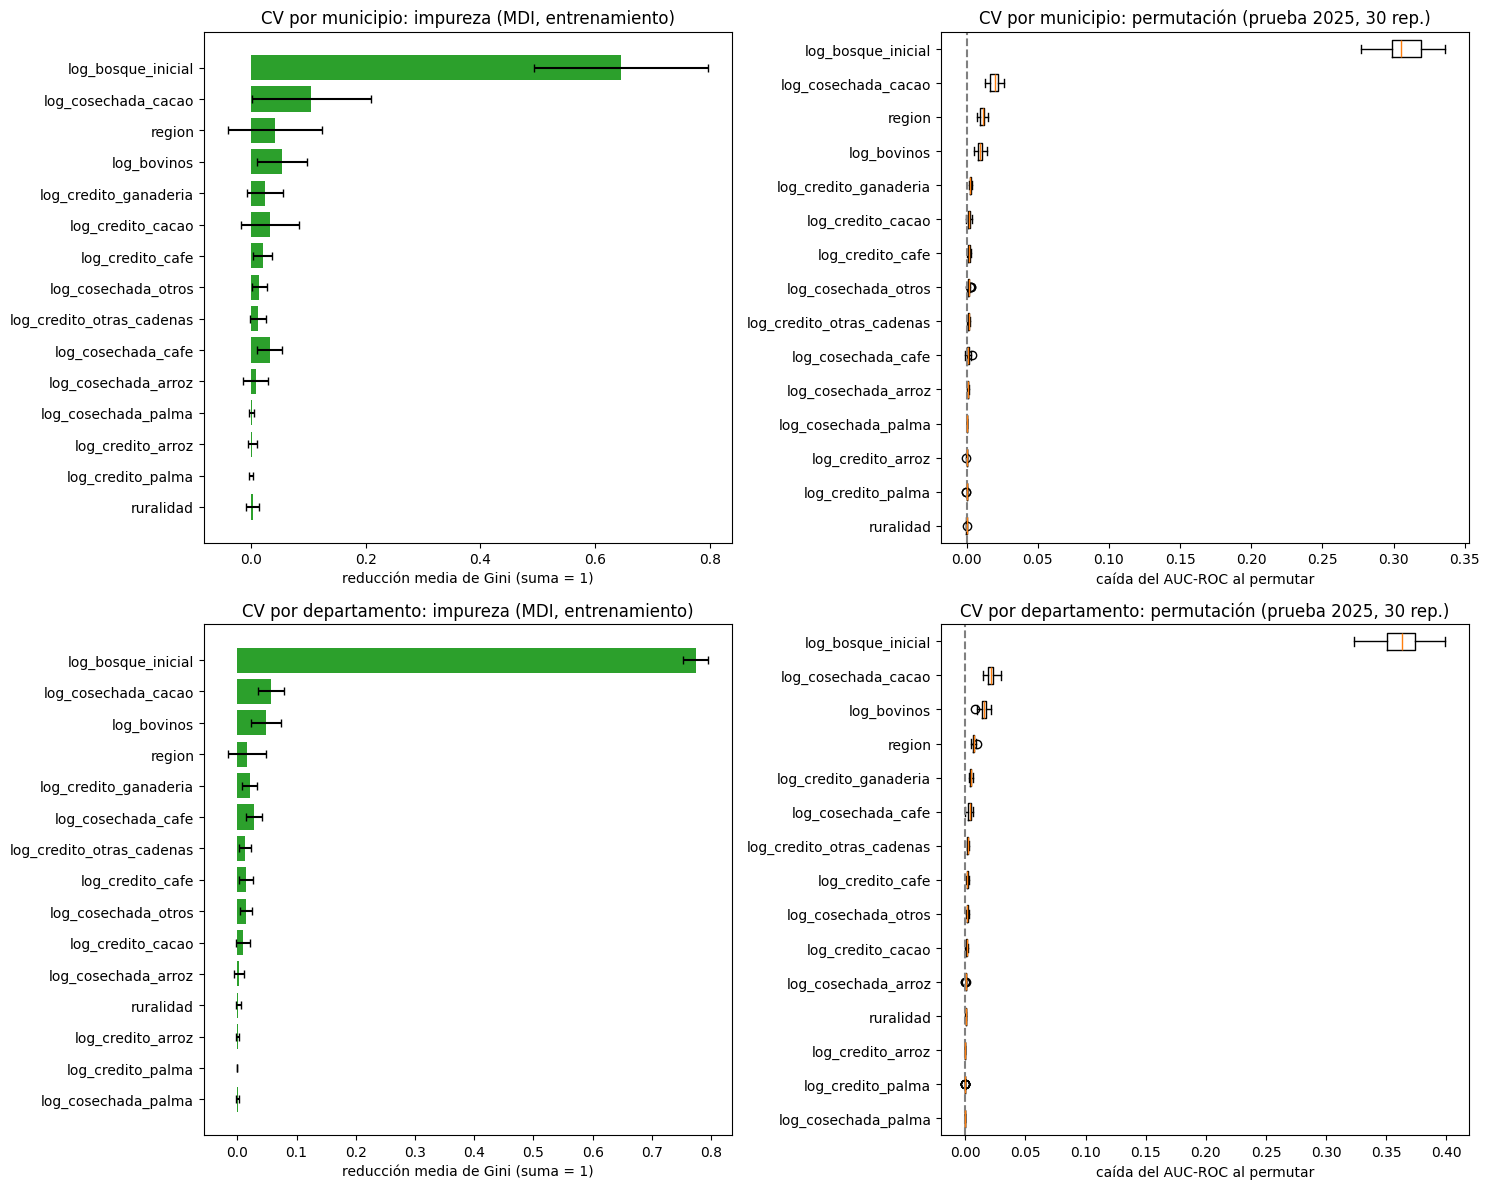

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(15, 12))
for fila, ag in enumerate(AGRUPACIONES):
    t = importancia[ag]
    orden = t.index[::-1]
    ax[fila, 0].barh(orden, t.loc[orden, "MDI"], xerr=t.loc[orden, "MDI_sd"], color="C2", capsize=3)
    ax[fila, 0].set_title(f"CV por {ag}: impureza (MDI, entrenamiento)"); ax[fila, 0].set_xlabel("reducción media de Gini (suma = 1)")
    ax[fila, 1].boxplot(pd.DataFrame(perms[ag].importances.T, columns=X_COLS)[orden].values, vert=False, labels=orden)
    ax[fila, 1].axvline(0, ls="--", color="grey")
    ax[fila, 1].set_title(f"CV por {ag}: permutación (prueba 2025, 30 rep.)"); ax[fila, 1].set_xlabel("caída del AUC-ROC al permutar")
plt.tight_layout(); plt.show()

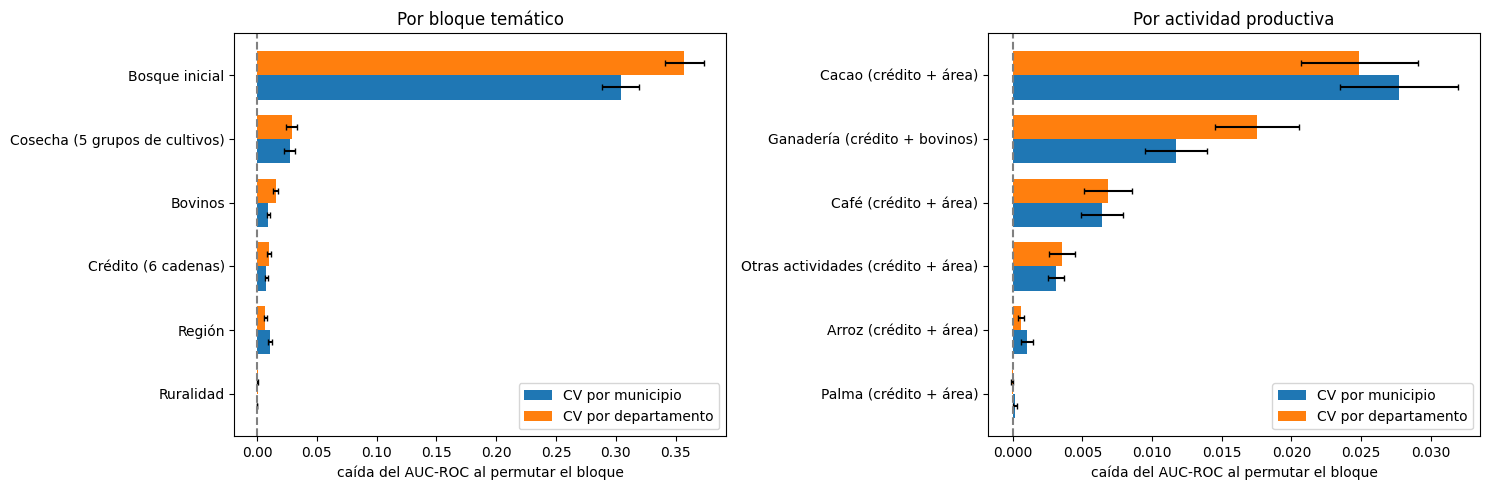

CV por municipio                   CV por departamento                  
                                    n_variables caida_AUC      sd         n_variables caida_AUC      sd
bloque                                                                                                 
Bosque inicial                                1    0.3041  0.0154                   1    0.3573  0.0163
Cosecha (5 grupos de cultivos)                5    0.0272  0.0046                   5    0.0290  0.0048
Región                                        1    0.0107  0.0016                   1    0.0068  0.0012
Bovinos                                       1    0.0095  0.0015                   1    0.0155  0.0020
Crédito (6 cadenas)                           6    0.0079  0.0016                   6    0.0099  0.0016
Ruralidad                                     1    0.0000  0.0002                   1    0.0004  0.0002

CV por municipio                   CV por departamento                  
                                        n_variables caida_AUC      sd         n_variables caida_AUC      sd
bloque                                                                                                     
Cacao (crédito + área)                            2    0.0277  0.0042                   2    0.0249  0.0042
Ganadería (crédito + bovinos)                     2    0.0117  0.0022                   2    0.0175  0.0030
Café (crédito + área)                             2    0.0064  0.0015                   2    0.0068  0.0017
Otras actividades (crédito + área)                2    0.0031  0.0006                   2    0.0035  0.0010
Arroz (crédito + área)                            2    0.0010  0.0004                   2    0.0006  0.0002
Palma (crédito + área)                            2    0.0001  0.0001                   2   -0.0001  0.0001

In [15]:
def permutar_bloques(modelo, X, y, bloques, n_repeats=30, semilla=SEMILLA):
    """Caida del AUC al desordenar juntas (con la misma permutacion de filas) las columnas de cada bloque."""
    rng = np.random.default_rng(semilla)
    base = roc_auc_score(y, modelo.predict_proba(X)[:, 1])
    filas = []
    for nombre, cols in bloques.items():
        caidas = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]
            caidas.append(base - roc_auc_score(y, modelo.predict_proba(Xp)[:, 1]))
        filas.append({"bloque": nombre, "n_variables": len(cols), "caida_AUC": np.mean(caidas), "sd": np.std(caidas)})
    return pd.DataFrame(filas).set_index("bloque").sort_values("caida_AUC", ascending=False)


BLOQUES = {"Crédito (6 cadenas)": CREDITO, "Cosecha (5 grupos de cultivos)": COSECHA, "Bovinos": ["log_bovinos"],
           "Bosque inicial": ["log_bosque_inicial"], "Región": ["region"], "Ruralidad": ["ruralidad"]}
ACTIVIDADES = {"Ganadería (crédito + bovinos)": ["log_credito_ganaderia", "log_bovinos"],
               "Café (crédito + área)": ["log_credito_cafe", "log_cosechada_cafe"],
               "Arroz (crédito + área)": ["log_credito_arroz", "log_cosechada_arroz"],
               "Cacao (crédito + área)": ["log_credito_cacao", "log_cosechada_cacao"],
               "Palma (crédito + área)": ["log_credito_palma", "log_cosechada_palma"],
               "Otras actividades (crédito + área)": ["log_credito_otras_cadenas", "log_cosechada_otros"]}
imp_bloques = {ag: permutar_bloques(f, X_test, y_test, BLOQUES) for ag, f in finales.items()}
imp_actividades = {ag: permutar_bloques(f, X_test, y_test, ACTIVIDADES) for ag, f in finales.items()}

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for eje, tablas, titulo in [(ax[0], imp_bloques, "Por bloque temático"), (ax[1], imp_actividades, "Por actividad productiva")]:
    orden = tablas["departamento"].sort_values("caida_AUC").index
    yy, h = np.arange(len(orden)), 0.38
    for k, (ag, color) in enumerate(zip(AGRUPACIONES, ["C0", "C1"])):
        t = tablas[ag].loc[orden]
        eje.barh(yy + (k - 0.5) * h, t.caida_AUC, height=h, xerr=t.sd, color=color, capsize=2, label=f"CV por {ag}")
    eje.set_yticks(yy, orden); eje.axvline(0, ls="--", color="grey")
    eje.set_xlabel("caída del AUC-ROC al permutar el bloque"); eje.set_title(titulo); eje.legend()
plt.tight_layout(); plt.show()
display(pd.concat({f"CV por {ag}": t for ag, t in imp_bloques.items()}, axis=1).round(4))
pd.concat({f"CV por {ag}": t for ag, t in imp_actividades.items()}, axis=1).round(4)

### Dependencia parcial

Cómo cambia la probabilidad media predicha al mover una variable, promediando sobre las demás, para los dos
modelos (línea continua: CV por municipio; discontinua: CV por departamento). Las marcas del eje x son los
deciles de los datos. Se muestran las 8 variables numéricas más importantes por permutación en el modelo con CV
por departamento.

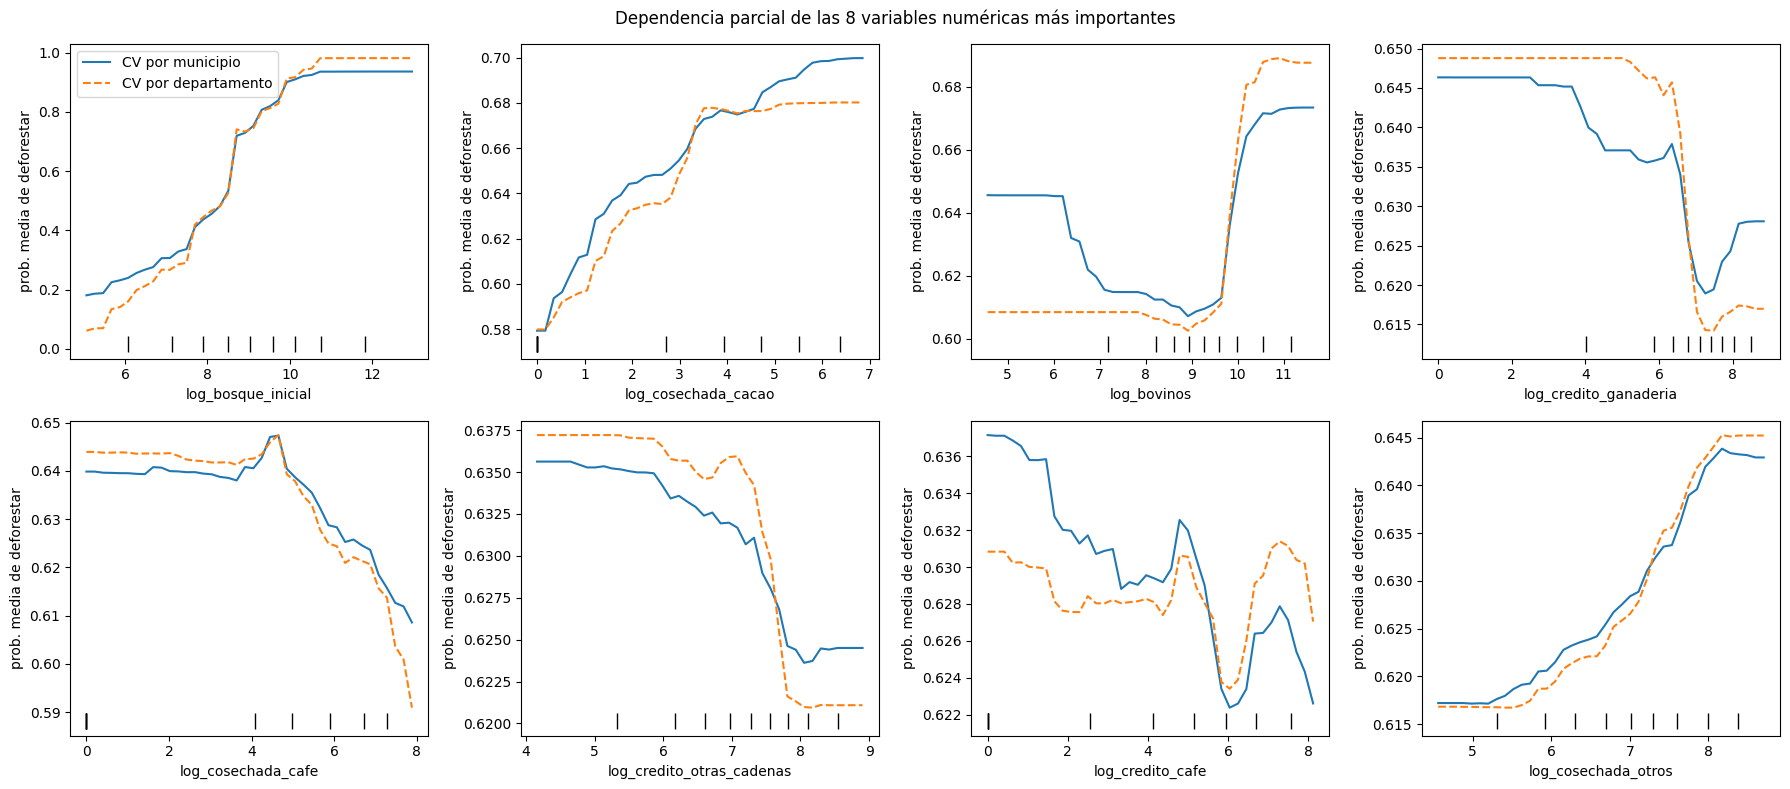

In [16]:
from sklearn.inspection import partial_dependence

top_num = [c for c in importancia["departamento"].index if c in NUMERICAS][:8]
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for eje, var in zip(ax.ravel(), top_num):
    for ag, estilo in zip(AGRUPACIONES, ["-", "--"]):
        pd_var = partial_dependence(finales[ag], X_train, [var], grid_resolution=40, kind="average",
                                    response_method="predict_proba")
        eje.plot(pd_var["grid_values"][0], pd_var["average"][0], estilo, label=f"CV por {ag}")
    deciles = np.nanpercentile(X_train[var], np.arange(10, 100, 10))
    eje.plot(deciles, np.full(len(deciles), eje.get_ylim()[0]), "|", color="black", ms=12)
    eje.set_xlabel(var); eje.set_ylabel("prob. media de deforestar")
ax.ravel()[0].legend()
fig.suptitle("Dependencia parcial de las 8 variables numéricas más importantes")
plt.tight_layout(); plt.show()

In [17]:
# Dependencia parcial de las categoricas
filas = []
for var in CATEGORICAS:
    for cat in X_train[var].dropna().unique():
        filas.append({"variable": var, "categoria": cat,
                      **{f"prob_media CV por {ag}": f.predict_proba(X_train.assign(**{var: cat}))[:, 1].mean()
                         for ag, f in finales.items()}})
pd.DataFrame(filas).sort_values(["variable", "prob_media CV por departamento"], ascending=[True, False]).round(3)

,variable,categoria,prob_media CV por municipio,prob_media CV por departamento
1,region,Caribe,0.656,0.657
0,region,Eje cafetero,0.638,0.628
5,region,Llano,0.640,0.626
4,region,Pacífico,0.630,0.625
3,region,Centro Sur,0.633,0.623
2,region,Centro Oriente,0.609,0.617
6,ruralidad,Rural,0.629,0.630
7,ruralidad,Rural disperso,0.630,0.628


## 13. Comparación de especificaciones

Se comparan con el AUC-ROC, con los hiperparámetros elegidos por cada agrupación, entrenando con 2022–2024 (el
modelo C necesita la deforestación del año anterior, que no existe para 2021) y evaluando en 2025.

| Modelo | Variables |
|---|---|
| A. Estructural | `log_bosque_inicial`, región, ruralidad |
| B. Principal | A + crédito por cadena, cosecha por cultivo y bovinos (*t − 1*) |
| C. Con persistencia | B + deforestación del año anterior (`log_def_l1`) |

In [18]:
especificaciones = {"A. Estructural": ["log_bosque_inicial"], "B. Principal": NUMERICAS,
                    "C. Con persistencia": NUMERICAS + ["log_def_l1"]}
train_c = train[train.anio >= 2022]
filas = []
for ag in AGRUPACIONES:
    for nombre, num in especificaciones.items():
        m = Pipeline([("pre", preprocesador(num)), ("rf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1, **mejores[ag]))])
        m.fit(train_c[num + CATEGORICAS], train_c.deforesta)
        filas.append({"modelo": nombre, "agrupacion_cv": f"CV por {ag}",
                      **metricas(y_test, m.predict_proba(test[num + CATEGORICAS])[:, 1])})
comparacion = pd.DataFrame(filas).pivot(index="modelo", columns="agrupacion_cv", values="AUC-ROC")
comparacion.round(4)

agrupacion_cv,CV por departamento,CV por municipio
modelo,,
A. Estructural,0.9064,0.9055
B. Principal,0.9240,0.9218
C. Con persistencia,0.9265,0.9277


## 14. Guardado

En `datos/analisis/modelo_random_forest_rural_departamento/`, una carpeta ignorada por git. El `joblib` guarda un
diccionario con los dos modelos (`"municipio"` y `"departamento"`). La carpeta del notebook original
(`modelo_random_forest_rural/`) no se toca.

In [19]:
SALIDA = Path("datos/analisis/modelo_random_forest_rural_departamento")
SALIDA.mkdir(parents=True, exist_ok=True)
joblib.dump({ag: {"modelo": finales[ag], "umbral": UMBRAL, "variables": X_COLS, "hiperparametros": mejores[ag],
                  "agrupacion_cv": ag, "regla_objetivo": REGLA_OBJETIVO, "bosque_min_ha": BOSQUE_MIN_HA}
             for ag in AGRUPACIONES}, SALIDA / "modelo_random_forest.joblib", compress=3)
test[["cod_dane", "nombre_departamento", "nombre_municipio", "anio", "def_ideam_ha", "deforesta"]].assign(
    **{f"prob_rf_cv_{ag}": prob_test[ag] for ag in AGRUPACIONES}, **{f"pred_rf_cv_{ag}": pred_test[ag] for ag in AGRUPACIONES},
    prob_rf_totales=prob_ant, prob_persistencia=prob_pers).to_csv(SALIDA / "predicciones_prueba.csv", index=False)
pd.concat(importancia, names=["agrupacion_cv"]).to_csv(SALIDA / "importancia_variables.csv")
pd.concat({ag: pd.concat({"bloque": imp_bloques[ag], "actividad": imp_actividades[ag]}) for ag in AGRUPACIONES},
          names=["agrupacion_cv"]).to_csv(SALIDA / "importancia_bloques.csv")
pd.concat(tablas_cv, names=["agrupacion_cv"]).to_csv(SALIDA / "grid_search_resultados.csv")
resumen_cv.to_csv(SALIDA / "resumen_hiperparametros.csv")
eval_territorio.to_csv(SALIDA / "evaluacion_territorios_fuera.csv", index=False)
pd.concat({"evaluacion": tabla_eval, "especificaciones": comparacion}).to_csv(SALIDA / "metricas.csv")
print(sorted(f.name for f in SALIDA.iterdir()))

['evaluacion_territorios_fuera.csv', 'grid_search_resultados.csv', 'importancia_bloques.csv', 'importancia_variables.csv', 'metricas.csv', 'modelo_random_forest.joblib', 'predicciones_prueba.csv', 'resumen_hiperparametros.csv']


## 15. Conclusiones

### 15.1 Configuración e hiperparámetros

- **Muestra y partición:** las mismas de `random_forest.ipynb` y del gradient boosting. Son 639 municipios rurales y
  rurales dispersos con bosque. El entrenamiento 2021–2024 tiene 2.556 filas y la prueba 2025, 639 filas.
- **Grupos:** 639 municipios o 31 departamentos. Con 5 pliegues por departamento, cada validación deja fuera unos
  6 departamentos completos.

| | CV por municipio | CV por departamento |
|---|---|---|
| Árboles · `max_depth` · `min_samples_leaf` | 300 · 12 · 25 | 600 · 8 · 25 |
| `max_features` · `class_weight` | 0,5 · ninguno | **todas (1,0)** · ninguno |
| AUC de validación (desv. entre pliegues) | 0,911 (0,008) | **0,899 (0,020)** |
| AUC de la misma combinación con la otra CV | 0,898 con CV por departamento | 0,910 con CV por municipio |
| AUC *out-of-bag* | 0,922 | 0,922 |

- **Agrupar por departamento baja el AUC de validación en 0,012 y duplica su variabilidad entre pliegues.** Parte
  del 0,911 de la versión original venía de validar con municipios cuyos vecinos de departamento sí estaban en el
  ajuste. El 0,899 es una estimación más realista para un departamento nuevo.
- **La superficie de la grilla es plana.** Cada combinación ganadora queda a 0,001 de la otra cuando se mide con
  la otra agrupación. Lo que cambia es sobre todo `max_features`: con departamentos fuera conviene que cada división
  vea todas las variables.

### 15.2 Comparación de modelos en 2025 (639 municipios rurales)

| Modelo | AUC-ROC | Falsos positivos | Falsos negativos | Aciertos |
|---|---|---|---|---|
| Gradient boosting (equipo) | **0,928** | 50 | **50** | 539 (84,4 %) |
| RF por actividad — CV por municipio | 0,925 | **44** | 55 | **540 (84,5 %)** |
| RF por actividad — CV por departamento | 0,925 | 46 | 55 | 538 (84,2 %) |
| RF de totales (9 variables) | 0,920 | 55 | 47 | 537 (84,0 %) |
| Persistencia (año anterior) | 0,827 | 50 | 52 | 537 (84,0 %) |

- **Los dos Random Forest son prácticamente el mismo modelo en 2025.** El AUC difiere en 0,0001, las probabilidades
  tienen una correlación de 0,995 y la versión por departamento acierta solo 2 municipios menos (2 falsos
  positivos más).
- La versión por municipio reproduce exactamente los resultados de `random_forest.ipynb`.

### 15.3 Generalización a territorios nuevos (2021–2025, 3.195 filas)

| Modelo | AUC, municipios fuera | AUC, departamentos fuera | Exactitud balanceada, departamentos fuera |
|---|---|---|---|
| RF — CV por municipio | **0,912** | 0,906 | 0,813 |
| RF — CV por departamento | 0,911 | 0,907 | **0,814** |
| Gradient boosting (equipo) | — | **0,909** | 0,813 |

- **Dejar fuera departamentos completos cuesta unas 0,005 de AUC frente a dejar fuera municipios sueltos**, y unas
  0,018 frente a la prueba de 2025, donde los municipios ya eran conocidos.
- Con departamentos fuera, **el Random Forest queda prácticamente empatado con el gradient boosting** (AUC 0,907
  frente a 0,909, exactitud balanceada 0,814 frente a 0,813). Los hiperparámetros elegidos por departamento ganan
  por muy poco en esa prueba (+0,0006), y los elegidos por municipio ganan por muy poco en la suya (+0,0015).

### 15.4 Importancia de las variables

**Por bloque** (caída del AUC al permutar en 2025, CV por municipio → CV por departamento): bosque 0,304 → **0,357**
· cosecha 0,027 → 0,029 · bovinos 0,010 → **0,016** · crédito 0,008 → 0,010 · región 0,011 → **0,007** ·
ruralidad 0,000 → 0,000.

**Por actividad:** cacao 0,028 → 0,025 · **ganadería 0,012 → 0,018** · café 0,006 → 0,007 · otras 0,003 → 0,004 ·
arroz 0,001 → 0,001 · palma 0,000 → 0,000.

- **El orden de las actividades no cambia:** el bosque domina, el cacao es la actividad más asociada con la
  deforestación, le sigue la ganadería y luego el café. El crédito, por sí solo, aporta poco.
- **El modelo por departamento se apoya más en el bosque y en los bovinos y menos en la región.** Tiene sentido: al
  validar en departamentos que no vio, la región aprendida en otros departamentos transfiere peor, y las variables
  propias del municipio ganan peso. Con `max_features = 1,0`, además, el bosque compite en todas las divisiones.
- La dependencia parcial de la región conserva el mismo orden en los dos modelos: el Caribe es la región con mayor
  probabilidad (0,66).

**Especificaciones** (AUC en 2025, entrenando con 2022–2024), CV por municipio → CV por departamento: estructural
0,906 → 0,906 · principal 0,922 → 0,924 · con persistencia 0,928 → 0,927.

### 15.5 En resumen

Agrupar la validación por departamento, como en el gradient boosting, **no cambia ni el desempeño ni las
conclusiones del Random Forest**. Sí da una estimación más honesta de cómo le iría en un departamento nuevo (AUC de
validación 0,899 en vez de 0,911). En esa prueba de territorio, el Random Forest y el gradient boosting quedan
empatados. Para comparar con el gradient boosting en igualdad de condiciones, conviene reportar la versión por
departamento.